# Linear Regression
### Performance & Diagnostics on California Housing

---

### 🎯 Objectives
- **Baseline Performance Benchmark**: Establish a foundational reference model by evaluating Ordinary Least Squares (OLS) prediction accuracy ($R^2$, RMSE, MAE) on California housing prices.
- **Interpretability & Error Diagnostics**: Identify primary price drivers through standardized coefficients ($\beta$) and diagnose residual error patterns across demographic income tiers.

---

### 📋 Scope of Work
This notebook executes the following structured end-to-end workflow:
1. **Imports & Environment Setup**: Package imports, aesthetic styling, and environment validation.
2. **Dataset Loading & Feature Engineering**: Data ingestion (`data/dataset.csv`) and domain ratio calculation.
3. **Train / Test Split & Preprocessing Pipeline**: Leakage-free `ColumnTransformer` with imputation, scaling, and one-hot encoding.
4. **Model Training & Prediction**: Closed-form OLS parameter estimation and test-set prediction.
5. **Standalone Performance Metrics**: Goodness-of-fit ($R^2$), dollar error metrics (RMSE, MAE), and percentage accuracy tolerances.
6. **Model Interpretability (Coefficients $\beta$)**: Standardized feature weights identifying positive and negative price drivers.
7. **Diagnostic Visualizations**:
   - **7.1 Actual vs. Predicted**: Identity line alignment and $500k ceiling cap analysis.
   - **7.2 Residual Distribution**: Error symmetry, mean bias, and normality diagnostics.
8. **Demographic Subgroup Error**: Subgroup error analysis across 4 household income quartiles.
9. **Engineering Takeaways & Summary**: Practical deployment guidelines, performance trade-offs, and architecture recommendations.

---

## 1. Imports & Environment Setup
- **Library Ingestion**: Imports essential data science and machine learning libraries (`numpy`, `pandas`, `scikit-learn`, `matplotlib`, `seaborn`).
- **Visualization Settings**: Sets unified styling theme, font sizing, and DPI for crisp diagnostics.
- **Environment Verification**: Verifies Python and Scikit-Learn versions to guarantee reproducible results.

In [19]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.size"] = 11
plt.rcParams["figure.dpi"] = 120

print(f"Python: {sys.version.split()[0]} | Scikit-Learn: {sklearn.__version__}")

import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
plt.rcParams["mathtext.fontset"] = "dejavusans"


Python: 3.12.3 | Scikit-Learn: 1.9.1


## 2. Dataset Loading & Feature Engineering
- **Data Ingestion**: Loads the 1990 California Housing census dataset (`data/dataset.csv`) from local storage or remote fallback.
- **Feature Engineering**: Constructs 3 domain ratio features (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`).
- **Data Inspection**: Displays dataset dimensions and previews the enriched feature table.

In [20]:
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

candidates = [
    Path("data/dataset.csv"),
    Path("../data/dataset.csv")
]

local_path = next((p for p in candidates if p.exists()), None)
df = pd.read_csv(local_path) if local_path else pd.read_csv(DATA_URL)

# Engineer domain ratios
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

print(f"Dataset successfully loaded: {df.shape[0]:,} records, {df.shape[1]} columns")
df.head(3)


Dataset successfully loaded: 20,640 records, 13 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260


## 3. Train / Test Split & Preprocessing Pipeline
- **Partitioning**: Splits data into 80% training (N = 16,512) and 20% test (N = 4,128) using a fixed seed (42).
- **Numerical Pipeline**: Imputes missing values in `total_bedrooms` using median and standardizes continuous features (`StandardScaler`).
- **Categorical Pipeline**: Converts categorical `ocean_proximity` into one-hot binary indicator columns.

In [21]:
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
])

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print(f"Training samples: {X_train.shape[0]:,} | Test samples: {X_test.shape[0]:,}")


Training samples: 16,512 | Test samples: 4,128


## 4. Model Training & Prediction
- **Model Fitting**: Fits Scikit-learn's closed-form `LinearRegression()` on the processed training set.
- **Parameter Estimation**: Computes the optimal regression hyperplane ($\hat{\beta}$) via normal equations without iterative optimization.
- **Batch Prediction**: Generates continuous target predictions on unseen test split records ($N = 4,128$).

In [22]:
print("Fitting Linear Regression model...")
pipeline.fit(X_train, y_train)

print("Generating predictions on test set...")
y_pred = pipeline.predict(X_test)

print(f"✓ Training complete on {len(X_train):,} training records.")
print(f"✓ Predictions successfully generated for {len(y_pred):,} test samples.")

Fitting Linear Regression model...
Generating predictions on test set...
✓ Training complete on 16,512 training records.
✓ Predictions successfully generated for 4,128 test samples.


## 5. Standalone Performance Metrics
- **Variance Explained ($R^2$)**: Measures overall goodness-of-fit on unseen test data.
- **Dollar Errors**: Calculates Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE).
- **Percentage Accuracy**: Computes MAPE and prediction tolerance within +/- 10% and +/- 20% of true value.

In [23]:
def compute_rmse(y_true, y_pred):
    try:
        from sklearn.metrics import root_mean_squared_error
        return float(root_mean_squared_error(y_true, y_pred))
    except ImportError:
        return float(np.sqrt(mean_squared_error(y_true, y_pred)))

r2 = r2_score(y_test, y_pred)
rmse = compute_rmse(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
acc_10 = np.mean(np.abs(y_test - y_pred) / y_test <= 0.10) * 100
acc_20 = np.mean(np.abs(y_test - y_pred) / y_test <= 0.20) * 100

metrics_df = pd.DataFrame([{
    "Model": "Linear Regression (OLS)",
    "R² Score (% Variance)": f"{r2 * 100:.2f}% ({r2:.4f})",
    "RMSE ($)": f"${rmse:,.2f}",
    "MAE ($)": f"${mae:,.2f}",
    "MAPE (% Error)": f"{mape:.2f}%",
    "Within ±10% (%)": f"{acc_10:.2f}%",
    "Within ±20% (%)": f"{acc_20:.2f}%"
}])

print("=" * 80)
print("LINEAR REGRESSION: STANDALONE PERFORMANCE SUMMARY")
print("=" * 80)
print(metrics_df.T.to_string(header=False))

LINEAR REGRESSION: STANDALONE PERFORMANCE SUMMARY
Model                  Linear Regression (OLS)
R² Score (% Variance)          63.53% (0.6353)
RMSE ($)                            $69,127.04
MAE ($)                             $49,645.49
MAPE (% Error)                          28.89%
Within ±10% (%)                         25.65%
Within ±20% (%)                         48.04%


## 6. Model Interpretability: Regression Coefficients ($\beta$)
- **Coefficient Extraction**: Retrieves standardized linear weights ($\beta$) for all numerical and encoded features.
- **Relative Importance**: Leverages standardized scaling to directly compare feature influence on house prices.
- **Visualization**: Plots sorted positive drivers (e.g., `median_income`) versus negative drivers (e.g., inland proximity).

Model Intercept: $237,125.78

Top Linear Predictors:
                  Feature  Coefficient (Beta)     Abs Value
   ocean_proximity_ISLAND       112060.244452 112060.244452
            median_income        78904.439397  78904.439397
                 latitude       -56638.231159  56638.231159
                longitude       -56276.058852  56276.058852
   ocean_proximity_INLAND       -53617.840376  53617.840376
               population       -46320.285471  46320.285471
               households        40233.724848  40233.724848
 ocean_proximity_NEAR BAY       -24109.185132  24109.185132
ocean_proximity_<1H OCEAN       -18666.478553  18666.478553
        bedrooms_per_room        16809.104551  16809.104551


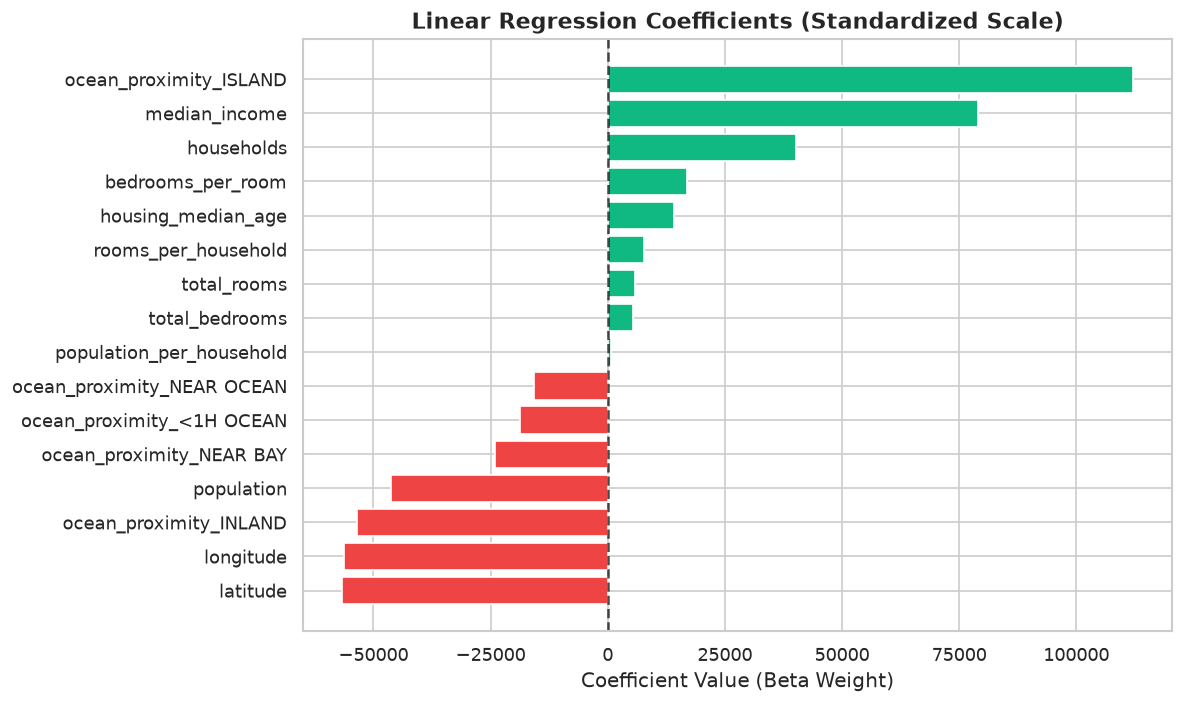

In [24]:
cat_encoder = pipeline.named_steps["preprocessor"].named_transformers_["cat"]
cat_names = list(cat_encoder.get_feature_names_out(cat_cols))
all_feature_names = num_cols + cat_names

coefs = pipeline.named_steps["regressor"].coef_
intercept = pipeline.named_steps["regressor"].intercept_

coef_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Coefficient (Beta)": coefs,
    "Abs Value": np.abs(coefs)
}).sort_values(by="Abs Value", ascending=False)

print(f"Model Intercept: ${intercept:,.2f}")
print("\nTop Linear Predictors:")
print(coef_df.head(10).to_string(index=False))

plt.figure(figsize=(10, 6))
colors = ["#10B981" if c > 0 else "#EF4444" for c in coef_df.sort_values(by="Coefficient (Beta)")["Coefficient (Beta)"]]
plt.barh(coef_df.sort_values(by="Coefficient (Beta)")["Feature"], coef_df.sort_values(by="Coefficient (Beta)")["Coefficient (Beta)"], color=colors)
plt.axvline(0, color="black", linestyle="--", alpha=0.7)
plt.title("Linear Regression Coefficients (Standardized Scale)", fontsize=13, fontweight="bold")
plt.xlabel("Coefficient Value (Beta Weight)")
plt.tight_layout()
plt.show()


## 7. Diagnostic Visualizations
Comprehensive visual inspection comparing model predictions against ground truth and evaluating error distributions.

### 7.1 Actual vs. Predicted Diagnostics
- **Identity Alignment**: Plots predictions against ground truth alongside the ideal line ($y = \hat{y}$).
- **Ceiling Truncation**: Visualizes the census $500k ceiling cap artifact where true prices were truncated.
- **Variance Spread**: Evaluates prediction dispersion across low-, medium-, and high-value properties.

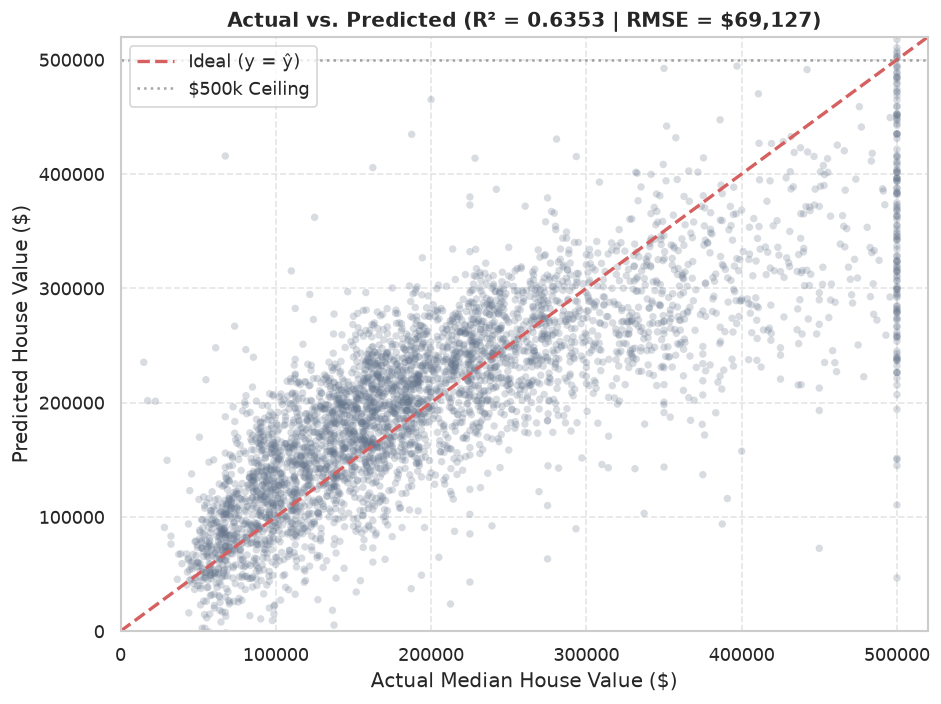

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))

lims = [0, 520000]

ax.scatter(y_test, y_pred, alpha=0.25, s=20, color="#64748B", edgecolors="none")
ax.plot(lims, lims, "r--", lw=2, label="Ideal (y = ŷ)")
ax.axhline(500001, color="gray", linestyle=":", alpha=0.7, label="$500k Ceiling")
ax.set_title(f"Actual vs. Predicted (R² = {r2:.4f} | RMSE = ${rmse:,.0f})", fontsize=12, fontweight="bold")
ax.set_xlabel("Actual Median House Value ($)")
ax.set_ylabel("Predicted House Value ($)")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.legend(loc="upper left")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 7.2 Residual Error Distribution
- **Error Histogram**: Plots 60-bin distribution of prediction residuals ($y_{\text{true}} - \hat{y}$) with KDE overlay.
- **Symmetry & Bias**: Evaluates residual mean and standard deviation to detect systematic prediction bias.
- **Zero-Error Reference**: Highlights the zero-error threshold to evaluate residual normality.

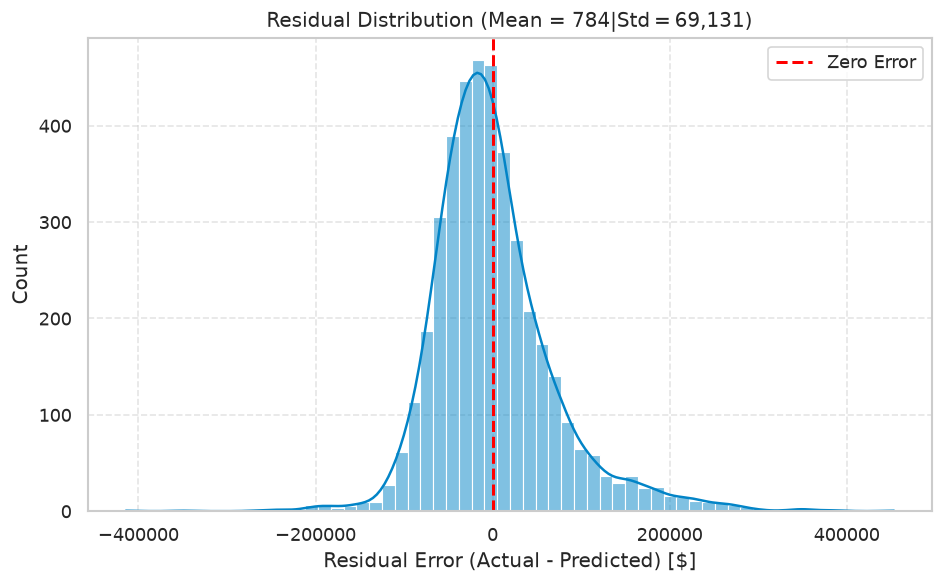

In [26]:
residuals = y_test - y_pred

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(residuals, bins=60, kde=True, ax=ax, color="#0284C7")
ax.axvline(0, color="red", linestyle="--", lw=1.8, label="Zero Error")
ax.set_title(f"Residual Distribution (Mean = ${residuals.mean():,.0f} | Std = ${residuals.std():,.0f})", fontsize=12, fontweight="bold")
ax.set_xlabel("Residual Error (Actual - Predicted) [$]")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 8. Demographic Subgroup Error (Income Quartiles)
- **Stratification**: Divides test census blocks into 4 household income quartiles (Low, Med-Low, Med-High, High).
- **Error Disaggregation**: Computes sample counts, median actual prices, MAE, and RMSE for each income tier.
- **Fairness Visualization**: Displays bar chart of error rates across tiers to reveal socioeconomic bias in linear models.

=== Linear Regression MAE ($) Across Income Quartiles ===
income_tier  samples  median_val     mean_mae   median_mae
        Low     1032    102700.0 39170.479510 28511.360856
 Medium-Low     1039    155700.0 46676.344176 35426.221306
Medium-High     1025    192400.0 54949.022240 42709.704011
       High     1032    288000.0 57842.236978 46733.006784


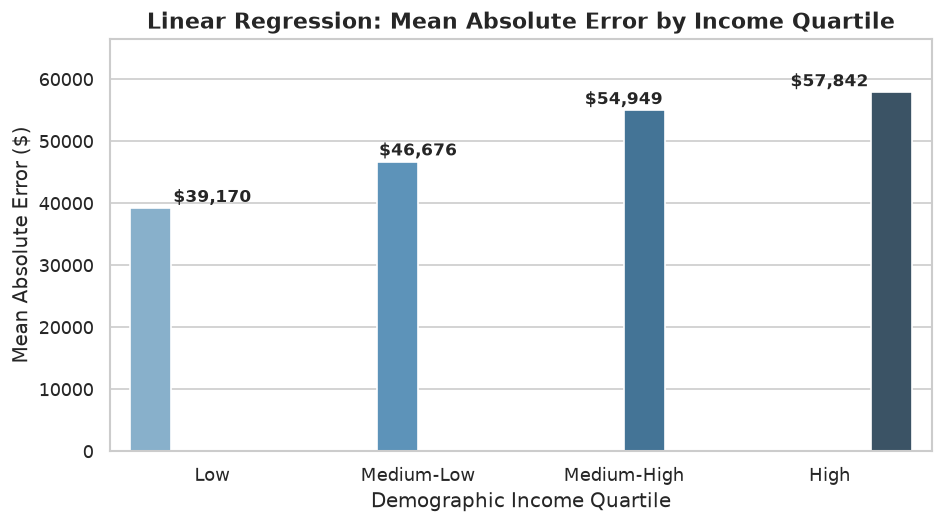

In [27]:
subgroup_df = X_test.copy()
subgroup_df["actual"] = y_test
subgroup_df["predicted"] = y_pred
subgroup_df["absolute_error"] = np.abs(y_test - y_pred)
subgroup_df["income_tier"] = pd.qcut(
    subgroup_df["median_income"], q=4, labels=["Low", "Medium-Low", "Medium-High", "High"]
)

tier_summary = subgroup_df.groupby("income_tier", observed=False).agg(
    samples=("actual", "count"),
    median_val=("actual", "median"),
    mean_mae=("absolute_error", "mean"),
    median_mae=("absolute_error", "median")
).reset_index()

print("=== Linear Regression MAE ($) Across Income Quartiles ===")
print(tier_summary.to_string(index=False))

plt.figure(figsize=(8, 4.5))
sns.barplot(data=tier_summary, x="income_tier", y="mean_mae", palette="Blues_d", hue="income_tier", legend=False)
plt.title("Linear Regression: Mean Absolute Error by Income Quartile", fontsize=13, fontweight="bold")
plt.xlabel("Demographic Income Quartile")
plt.ylabel("Mean Absolute Error ($)")
for i, val in enumerate(tier_summary["mean_mae"]):
    plt.text(i, val + 1000, f"${val:,.0f}", ha="center", fontsize=10, fontweight="bold")
plt.ylim(0, tier_summary["mean_mae"].max() * 1.15)
plt.tight_layout()
plt.show()


## 9. Engineering Takeaways & Summary
- **Standard Regression Baseline**: Provides a clean, well-calibrated linear reference model capturing **63.53%** of price variance on unseen test records.
- **Glass-Box Interpretability**: Standardized coefficients explicitly quantify the direct marginal dollar impact of each feature without black-box opacity.
- **Accuracy Ceiling ($R^2 \approx 63.5\%$)**: Constrained by the additive linear assumption; cannot model non-linear geographic coastline premiums or threshold effects without manual interaction terms.